In [1]:
import numpy as np
import pandas as pd
spotify_df = pd.read_csv('dataset2.csv', header=0)

In [2]:
display(spotify_df.head())
display(spotify_df.tail())

,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
0,Movie,Henri Salvador,C'est beau de faire un Show,0BRjO6ga9RKCKjfDqeFgWV,0,0.611,0.389,99373,0.910,0.000,C#,0.3460,-1.828,Major,0.0525,166.969,4/4,0.814
1,Movie,Martin & les fées,Perdu d'avance (par Gad Elmaleh),0BjC1NfoEOOusryehmNudP,1,0.246,0.590,137373,0.737,0.000,F#,0.1510,-5.559,Minor,0.0868,174.003,4/4,0.816
2,Movie,Joseph Williams,Don't Let Me Be Lonely Tonight,0CoSDzoNIKCRs124s9uTVy,3,0.952,0.663,170267,0.131,0.000,C,0.1030,-13.879,Minor,0.0362,99.488,5/4,0.368
3,Movie,Henri Salvador,Dis-moi Monsieur Gordon Cooper,0Gc6TVm52BwZD07Ki6tIvf,0,0.703,0.240,152427,0.326,0.000,C#,0.0985,-12.178,Major,0.0395,171.758,4/4,0.227
4,Movie,Fabien Nataf,Ouverture,0IuslXpMROHdEPvSl1fTQK,4,0.950,0.331,82625,0.225,0.123,F,0.2020,-21.150,Major,0.0456,140.576,4/4,0.390


,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
232720,Soul,Slave,Son Of Slide,2XGLdVl7lGeq8ksM6Al7jT,39,0.00384,0.687,326240,0.714,0.544000,D,0.0845,-10.626,Major,0.0316,115.542,4/4,0.962
232721,Soul,Jr Thomas & The Volcanos,Burning Fire,1qWZdkBl4UVPj9lK6HuuFM,38,0.03290,0.785,282447,0.683,0.000880,E,0.2370,-6.944,Minor,0.0337,113.830,4/4,0.969
232722,Soul,Muddy Waters,(I'm Your) Hoochie Coochie Man,2ziWXUmQLrXTiYjCg2fZ2t,47,0.90100,0.517,166960,0.419,0.000000,D,0.0945,-8.282,Major,0.1480,84.135,4/4,0.813
232723,Soul,R.LUM.R,With My Words,6EFsue2YbIG4Qkq8Zr9Rir,44,0.26200,0.745,222442,0.704,0.000000,A,0.3330,-7.137,Major,0.1460,100.031,4/4,0.489
232724,Soul,Mint Condition,You Don't Have To Hurt No More,34XO9RwPMKjbvRry54QzWn,35,0.09730,0.758,323027,0.470,0.000049,G#,0.0836,-6.708,Minor,0.0287,113.897,4/4,0.479


In [3]:
spotify_df.shape

(232725, 18)

In [4]:
spotify_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232725 entries, 0 to 232724
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   genre             232725 non-null  object 
 1   artist_name       232725 non-null  object 
 2   track_name        232724 non-null  object 
 3   track_id          232725 non-null  object 
 4   popularity        232725 non-null  int64  
 5   acousticness      232725 non-null  float64
 6   danceability      232725 non-null  float64
 7   duration_ms       232725 non-null  int64  
 8   energy            232725 non-null  float64
 9   instrumentalness  232725 non-null  float64
 10  key               232725 non-null  object 
 11  liveness          232725 non-null  float64
 12  loudness          232725 non-null  float64
 13  mode              232725 non-null  object 
 14  speechiness       232725 non-null  float64
 15  tempo             232725 non-null  float64
 16  time_signature    23

In [5]:
spotify_df.describe()

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
count,232725.000000,232725.000000,232725.000000,2.327250e+05,232725.000000,232725.000000,232725.000000,232725.000000,232725.000000,232725.000000,232725.000000
mean,41.127502,0.368560,0.554364,2.351223e+05,0.570958,0.148301,0.215009,-9.569885,0.120765,117.666585,0.454917
std,18.189948,0.354768,0.185608,1.189359e+05,0.263456,0.302768,0.198273,5.998204,0.185518,30.898907,0.260065
min,0.000000,0.000000,0.056900,1.538700e+04,0.000020,0.000000,0.009670,-52.457000,0.022200,30.379000,0.000000
25%,29.000000,0.037600,0.435000,1.828570e+05,0.385000,0.000000,0.097400,-11.771000,0.036700,92.959000,0.237000
50%,43.000000,0.232000,0.571000,2.204270e+05,0.605000,0.000044,0.128000,-7.762000,0.050100,115.778000,0.444000
75%,55.000000,0.722000,0.692000,2.657680e+05,0.787000,0.035800,0.264000,-5.501000,0.105000,139.054000,0.660000
max,100.000000,0.996000,0.989000,5.552917e+06,0.999000,0.999000,1.000000,3.744000,0.967000,242.903000,1.000000


# Defining the ML Problem
Our project is a supervised learning problem because the dataset we decided on uses both input features and a known target variable. The target we aim to predict is a track's popularity with a score from 0-100. Since this target is continuous and not categorical, the problem is specifically a regression one and not a classification problem. Our objective is to use features like, energy, loudness, tempo, valence, liveness, instrumentalness, speechiness, duration_ms, danceability, along with categorical variables like mode, key, time_signature, and track_genre. These will all help develop a model that is capable of estimating a song's popularity score. All in all, these characteristics define a supervised regression task, where our goal is to predict a numerical based on a variety of features.

In [6]:
display(spotify_df.isnull().sum())

genre               0
artist_name         0
track_name          1
track_id            0
popularity          0
acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
tempo               0
time_signature      0
valence             0
dtype: int64

In [7]:
display(spotify_df.duplicated().sum())

np.int64(0)

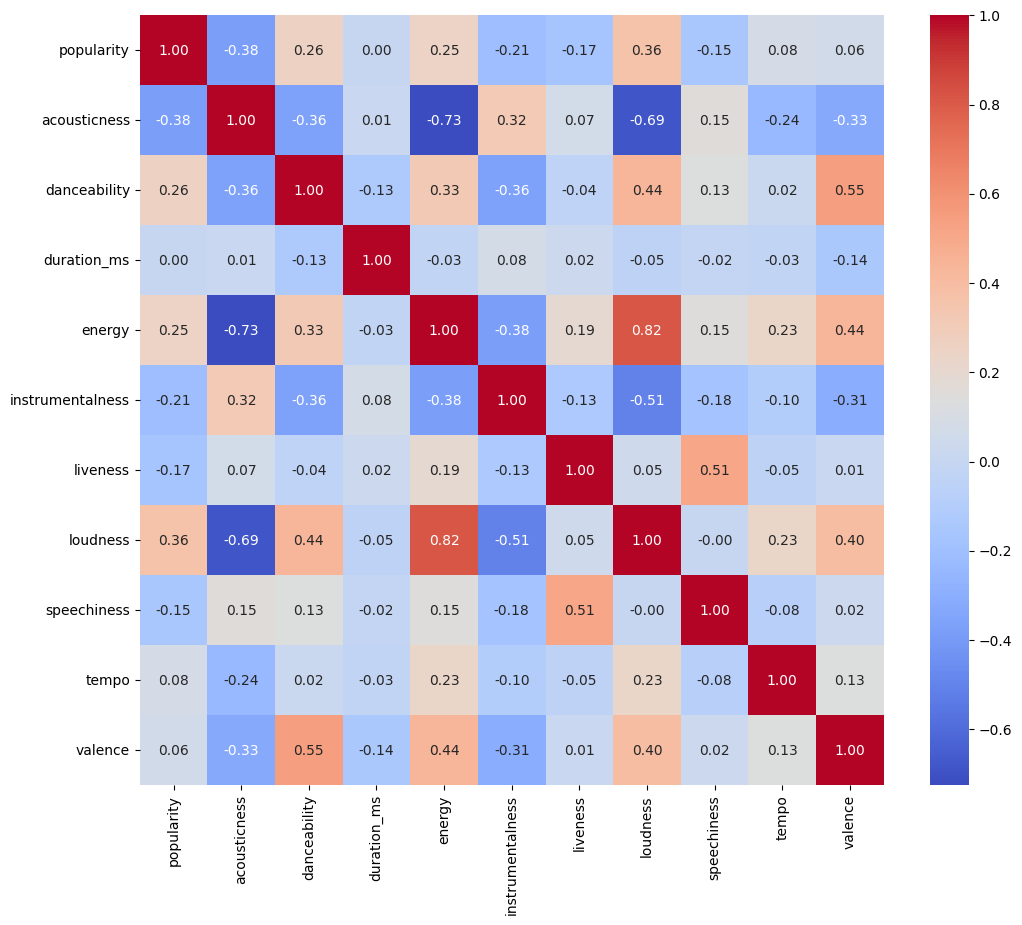

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

cat_dropped = spotify_df.copy().drop(["track_id", "artist_name", "track_name", "genre", "mode", "key", "time_signature"], axis=1)

plt.figure(figsize=(12, 10))
sns.heatmap(data=cat_dropped.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

# Project Plan
Before building the models here is our plan:

1. First we need to prepare data:
    - Drop the identifier columns that are not predictive like "track_id", "artists", "album_name", and "track_name".
    - Handle the missing values.
    - Removing duplicate rows.
    - Address multicollinearity by dropping highly correlated features like acousticness.
    - Treat the outliers for skewed features like instrumentalness and speechiness, using winsorization.
    - One-hot encode categorical variables such as mode, key, time_signature, and track_genre.
    - Standardize key numerical variables like duration_ms, speechiness, instrumentalness, danceability, energy, liveness, valence, tempo, and loudness.
2. After this we can work on modeling:
    - We can split the data into training and test sets
    - We can start with a baseline model(predict mean popularity) for comparison.
    - Train the models covered in class like Linear Regression, Decition Tree, Random Forest, Gradient Boosting, Linear SVR(if possible), and Simple NN usinf Keras.
3. Evaluation:
    - We will use R^2, MAE< and MSE to evaluate model performance on the test set.
    - We will compare against the baseline model to see if we actually learned something.
4. Optimization:
    - We will use Random Forest feature importances to select the most important features.
5. Error Analysis
    - Will track everything into popularity bins, whether its low, medium, high, or very high, and check how the model performs in each bin to see if errors are way larger in some.

In [9]:
numerical_features = ["duration_ms", "danceability", "energy", "loudness", "instrumentalness", "speechiness", "liveness", "valence", "tempo"]

def features_with_outliers(df):
    outlier_features = {}
    for col in df.select_dtypes(include='number'):
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        if not outliers.empty:
            outlier_features[col] = len(outliers)
    return outlier_features

outlier_counts = features_with_outliers(spotify_df)
for feature, count in outlier_counts.items():
    print(f"{feature}: {count} outliers ({np.round(count / len(spotify_df) * 100)}%)")

popularity: 38 outliers (0.0%)
duration_ms: 14651 outliers (6.0%)
instrumentalness: 51545 outliers (22.0%)
liveness: 21241 outliers (9.0%)
loudness: 14171 outliers (6.0%)
speechiness: 32979 outliers (14.0%)
tempo: 168 outliers (0.0%)


C:\Users\carp\.conda\envs\IntroMachineLearning\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)
C:\Users\carp\.conda\envs\IntroMachineLearning\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in sqrt
  result = func(self.values, **kwargs)


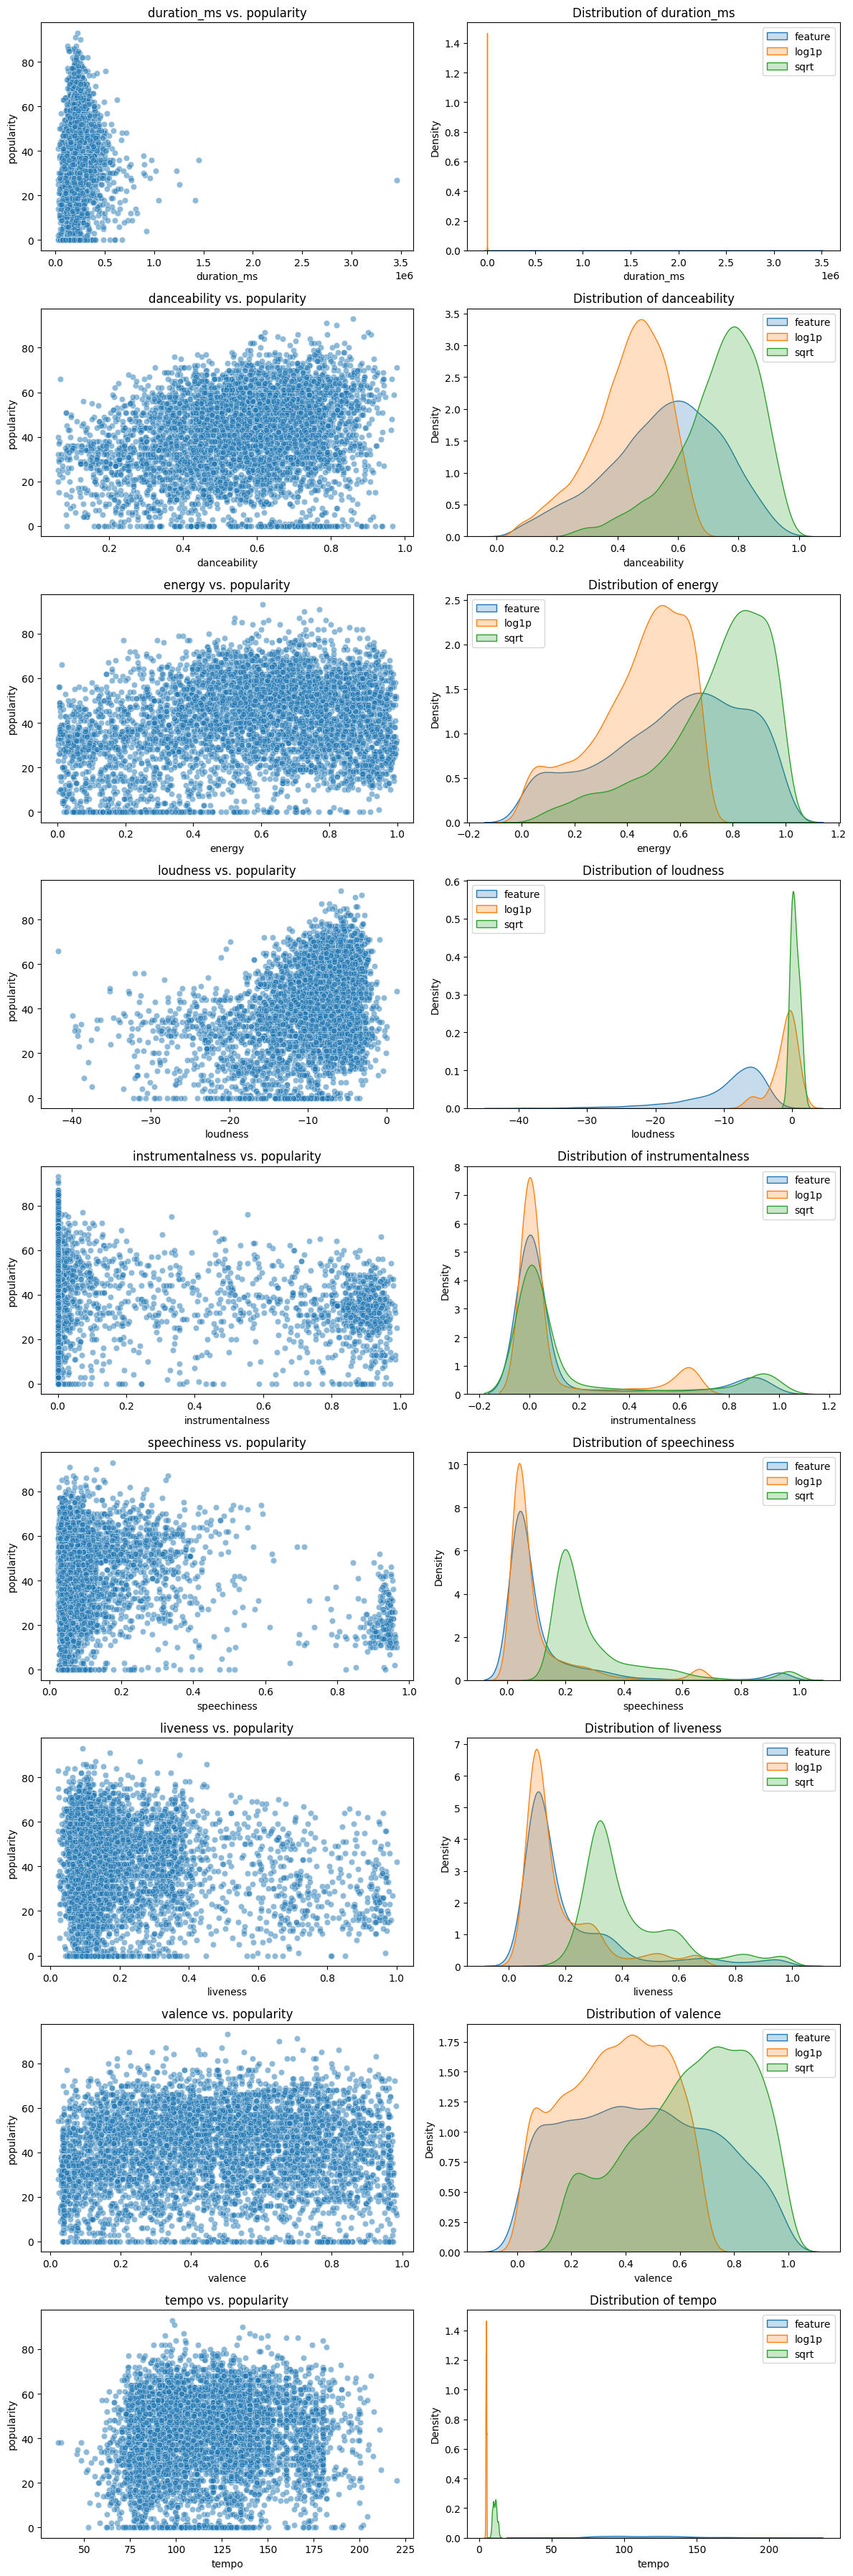

In [10]:
import math

n_features = len(numerical_features)
n_cols = 2  # scatterplot + distribution per feature
n_rows = n_features

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 4))

sample_df = spotify_df.sample(n=min(5000, len(spotify_df)), random_state=42)
data_nums = sample_df[numerical_features]
transformations = {
    'feature': data_nums,
    'log1p': np.log1p(data_nums),
    'sqrt': np.sqrt(data_nums)
}

for i, feature in enumerate(numerical_features):
    ax_scatter = axes[i, 0]
    ax_dist = axes[i, 1]

    sns.scatterplot(x=sample_df[feature], y=sample_df['popularity'], ax=ax_scatter, alpha=0.5)
    ax_scatter.set_title(feature + ' vs. popularity')
    ax_scatter.set_xlabel(feature)
    ax_scatter.set_ylabel('popularity')    

    for name, vals in transformations.items():
        sns.kdeplot(vals[feature], ax=ax_dist, label=name, fill=True)

    ax_dist.set_title('Distribution of ' + feature)
    ax_dist.set_xlabel(feature)
    ax_dist.legend()

plt.tight_layout()
plt.show()

In [11]:
cleaned_df = spotify_df.copy()

# Drop unnecessary features
cleaned_df = cleaned_df.drop(["track_id", "artist_name", "track_name"], axis=1)

# Drop null values
cleaned_df = cleaned_df.dropna()

# Get rid of duplicates
cleaned_df = cleaned_df.drop_duplicates()

# Remove anamolies
from scipy.stats.mstats import winsorize
for feature in outlier_counts.keys():
    cleaned_df[feature] = winsorize(cleaned_df[feature], limits=[0.01, 0.01])

 # Handle multicollinearity
#cleaned_df = cleaned_df.drop(["acousticness"], axis=1)

# Fix indexes
cleaned_df = cleaned_df.reset_index(drop=True)

# Sqrt transform
for feature in ["speechiness", "liveness", "tempo"]:
    cleaned_df[feature] = np.sqrt(cleaned_df[feature])

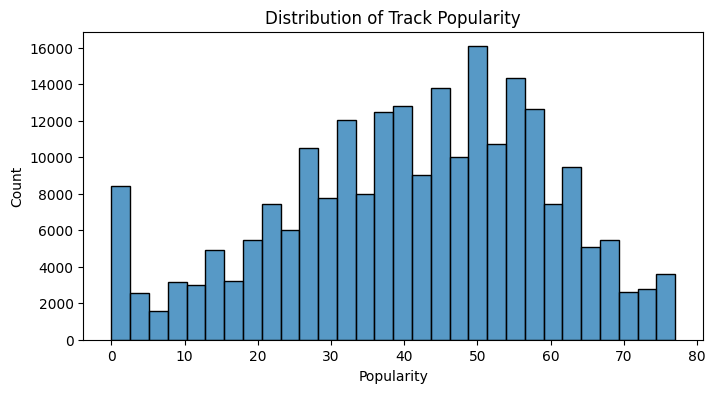

In [12]:
# 1) Popularity distribution
plt.figure(figsize=(8, 4))
sns.histplot(cleaned_df["popularity"], bins=30)
plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity")
plt.ylabel("Count")
plt.show()

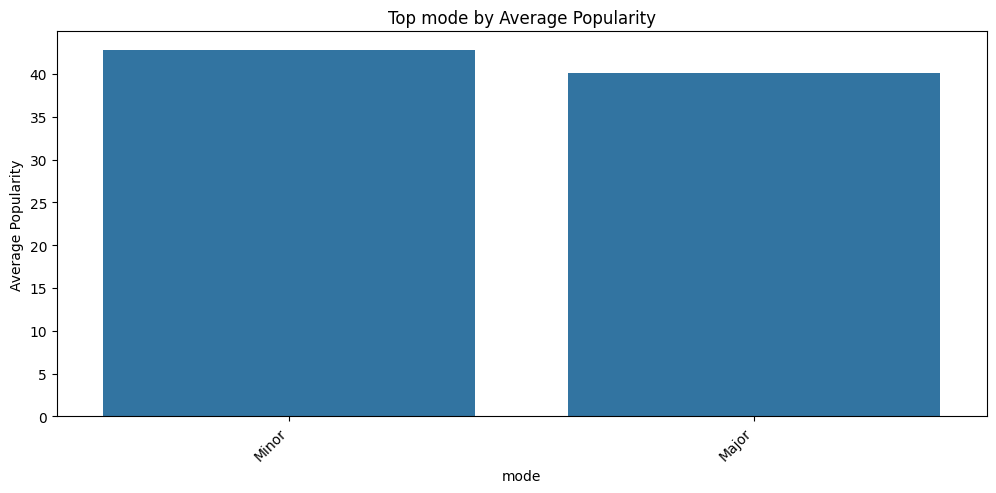

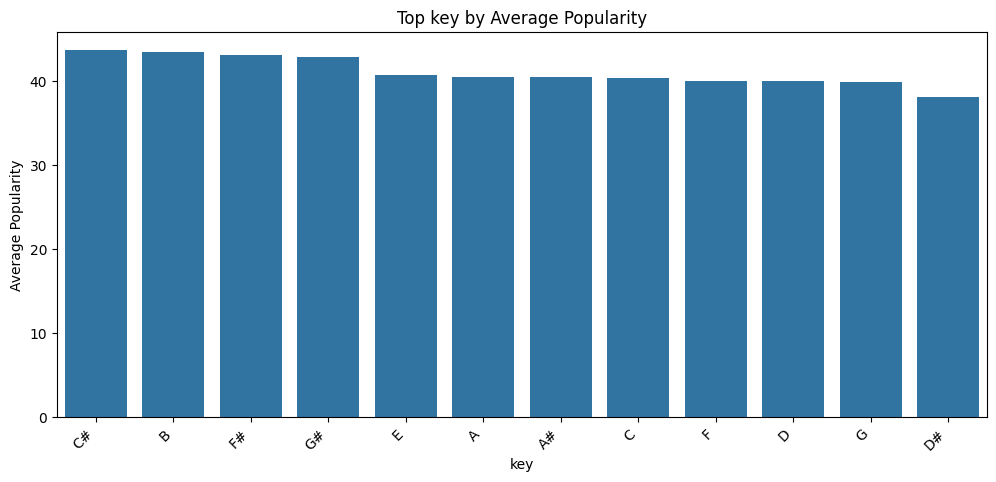

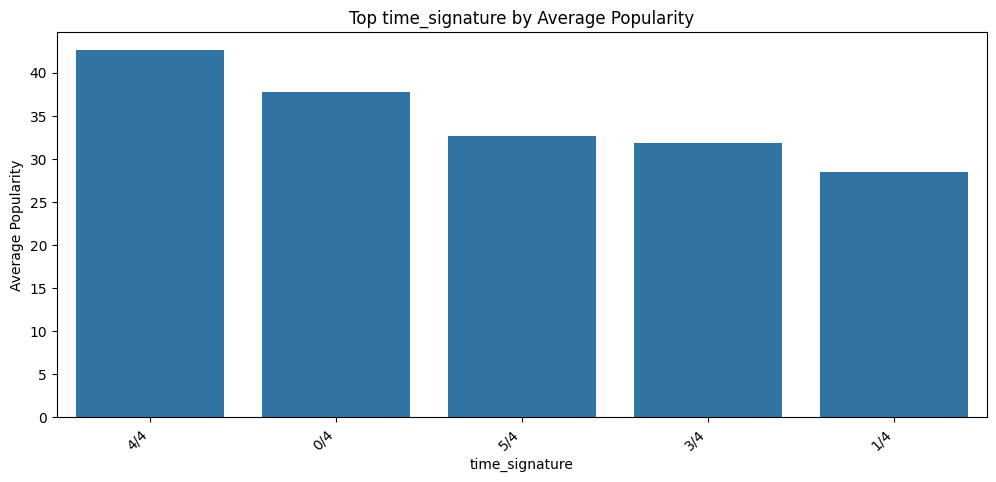

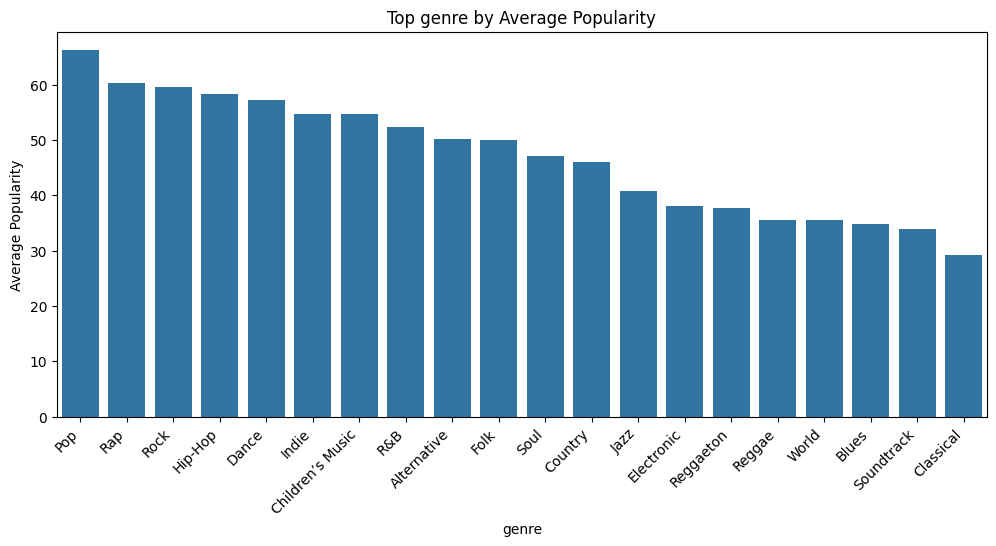

In [13]:
# 2) Average popularity by genre
categorical = ["mode", "key", "time_signature", "genre"]
for category in categorical:
    genre_popularity = (
        cleaned_df
        .groupby(category)["popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(20)
    )

    plt.figure(figsize=(12, 5))
    sns.barplot(x=genre_popularity.index, y=genre_popularity.values)
    plt.xticks(rotation=45, ha="right")
    plt.title("Top " + category + " by Average Popularity")
    plt.xlabel(category)
    plt.ylabel("Average Popularity")
    plt.show()

# Exploratory Data Analysis - Summary
From the correlation heatmap we can see that some features like energy, danceability, loudness, tempo, and valence show noticeable relationships with popularity. We can also see that certain features like acousticness are highly correlated with others, which is why we later drop them to reduce multicollinearity.

From the popularity histogram, we can see that the popularity is not uniform over 0-100. There are a lot more tracks in the low-medium range and fewer in the very high popularity tracks.

From the categorical plots we can see that some genres and combinations of musical attributes tend to have higher average popularity. This also confirms that both audio features and categorical features carry signal that should help with prediction. In conclusion, this analysis helps justify which features we keep, which we drop, and why predicting popularity is an important supervised regression problem.


In [14]:
# One hot encoding
to_encode = categorical
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(sparse_output=False)
new_df = pd.DataFrame(enc.fit_transform(cleaned_df[to_encode]))
new_df.columns = enc.get_feature_names_out(to_encode)
# Drop old columns, concat new ones to cleaned_df
encoded_df = cleaned_df.drop(to_encode, axis=1)
encoded_df = pd.concat([encoded_df, new_df], axis=1)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
numerical_columns = ["duration_ms", "speechiness", "instrumentalness", "danceability", "energy", "liveness", "valence", "tempo", "loudness", "acousticness"]
encoded_df[numerical_columns] = scaler.fit_transform(encoded_df[numerical_columns])

# Show final df
display(encoded_df)

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,...,genre_Pop,genre_R&B,genre_Rap,genre_Reggae,genre_Reggaeton,genre_Rock,genre_Ska,genre_Soul,genre_Soundtrack,genre_World
0,0,0.683468,-0.890726,-1.511383,1.286745,-0.489811,0.906085,1.269034,-0.384011,1.544490,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,-0.345390,0.192184,-1.078740,0.630109,-0.489811,-0.229585,0.681943,-0.017977,1.736538,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,1.644675,0.585479,-0.704230,-1.670012,-0.489811,-0.614443,-0.743800,-0.601239,-0.556774,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0.942796,-1.693479,-0.907344,-0.929874,-0.489811,-0.654772,-0.452311,-0.553826,1.675672,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,1.639038,-1.203207,-1.702065,-1.313228,-0.082986,0.116621,-1.989784,-0.471131,0.785075,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232636,39,-1.027989,0.714782,1.071578,0.542811,1.309480,-0.786516,-0.186355,-0.671099,-0.004466,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
232637,38,-0.946075,1.242767,0.572980,0.425148,-0.486900,0.329285,0.444605,-0.638617,-0.061454,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
232638,47,1.500917,-0.201112,-0.741881,-0.576885,-0.489811,-0.691400,0.215320,0.485550,-1.128455,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
232639,44,-0.300290,1.027263,-0.110199,0.504855,-0.489811,0.842620,0.411532,0.470972,-0.537394,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


# Data Preparation - Summary
For all our data preparation we did the following steps:
- Dropped identifier columns because they do not directly help predict popularity.
- Removed rows with missing values so that the model always sees complete data.
- Removed duplicate rows to avoid giving extra weight to repeated tracks.
- Reduced multicollinearity by dropping acousticness, which was heavily correlated to other audio features in the heatmap.
- Handled any outliers for instrumentalness and speechiness using winsorization so that the extreme values would not completely dominate the model.
- One-hot encoded categorical variablesto convert them to numeric features.
- Standardized key numeric variables so that the models that depend on feature scale work better.
Our result is encoded_df, which is our cleaned and fully numerical data dataset ready for modeling.

In [33]:
from sklearn.model_selection import train_test_split

target = encoded_df["popularity"]
training_df = encoded_df.copy().drop(["popularity"], axis=1)

X_train, X_test, y_train, y_test = train_test_split(training_df, target, test_size=0.2, random_state=42)

In [16]:
from sklearn.metrics import (
    mean_squared_error, 
    mean_absolute_error,
    r2_score
)
from sklearn.model_selection import cross_val_score

models = {}
results = {}
def evaluate(model, y_pred, id):
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = mse**(1/2)
    print("R^2 : ", r2)
    print("MAE : ", mae)
    print("MSE : ", mse)
    print("RMSE : ", rmse)
    results[id] = {"R2": r2, "MAE": mae, "MSE": mse, "RMSE": rmse}
    

    #New data visualizations
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Actual vs Predicted Scatter Plot
    sns.scatterplot(x=y_test, y=y_pred, ax=axes[0], alpha=0.5)
    axes[0].set_title('Actual vs. Predicted')
    axes[0].set_xlabel('Actual Popularity')
    axes[0].set_ylabel('Predicted Popularity')
    axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

    # Distribution Plot (Overlayed)
    sns.kdeplot(y_test, ax=axes[1], label='Actual', color='blue', fill=True)
    sns.kdeplot(y_pred, ax=axes[1], label='Predicted', color='orange', fill=True)
    axes[1].set_title('Distribution of Actual vs. Predicted')
    axes[1].set_xlabel('Popularity')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

def evaluate_sk(model, train=X_train, test=X_test, id=None):
    id = model.__class__.__name__ if id is None else id
    models[id] = {"model": model, "train": train, "test": test}
    model.fit(train, y_train)
    y_pred = model.predict(test)
    evaluate(model, y_pred, id)
    

R^2 :  -6.742955961258623e-05
MAE :  14.820443368090123
MSE :  327.68588983463763
RMSE :  18.10209628287944


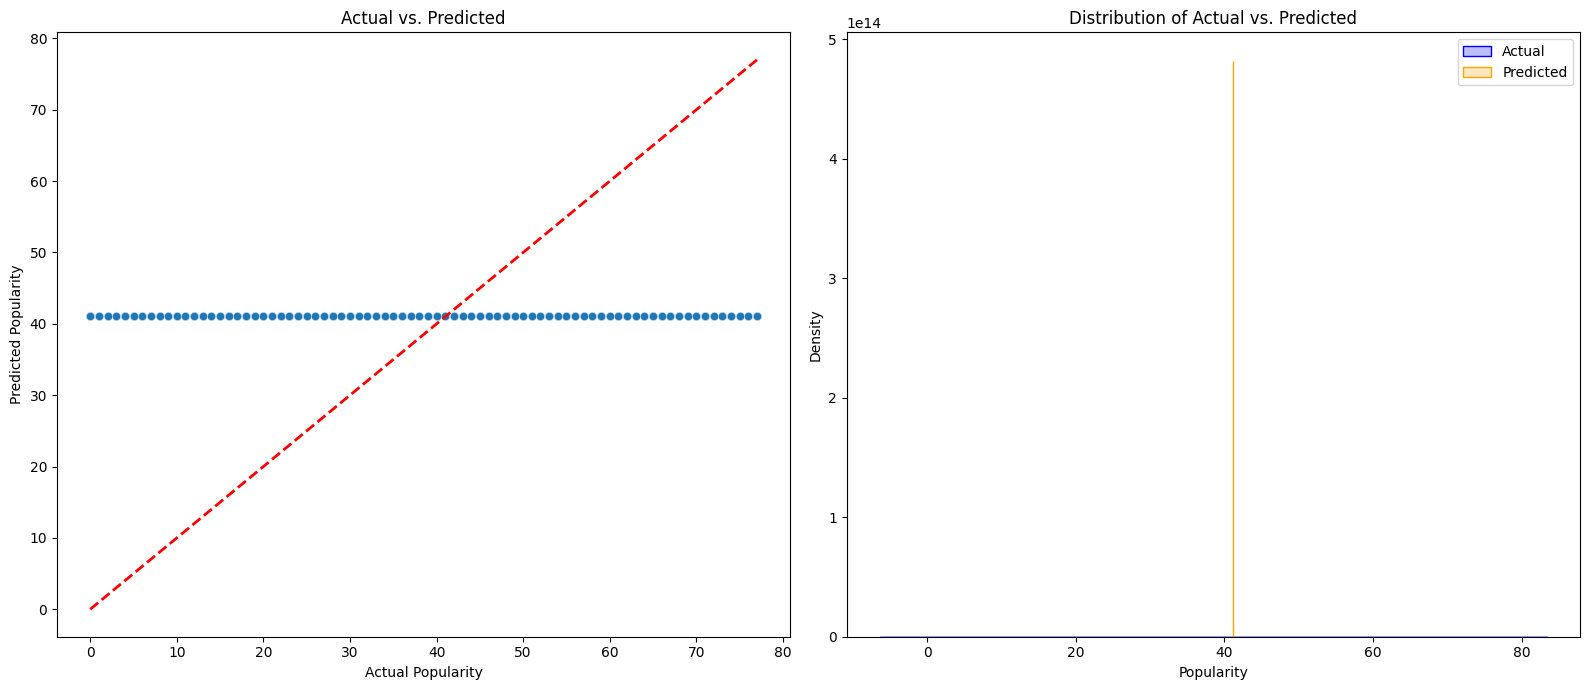

In [17]:
from sklearn.dummy import DummyRegressor
# this baseline model always predicts the mean popularity
evaluate_sk(DummyRegressor(strategy="mean"))

R^2 :  0.7287654271929668
MAE :  7.1772591679291295
MSE :  88.87374962639207
RMSE :  9.427287500993701


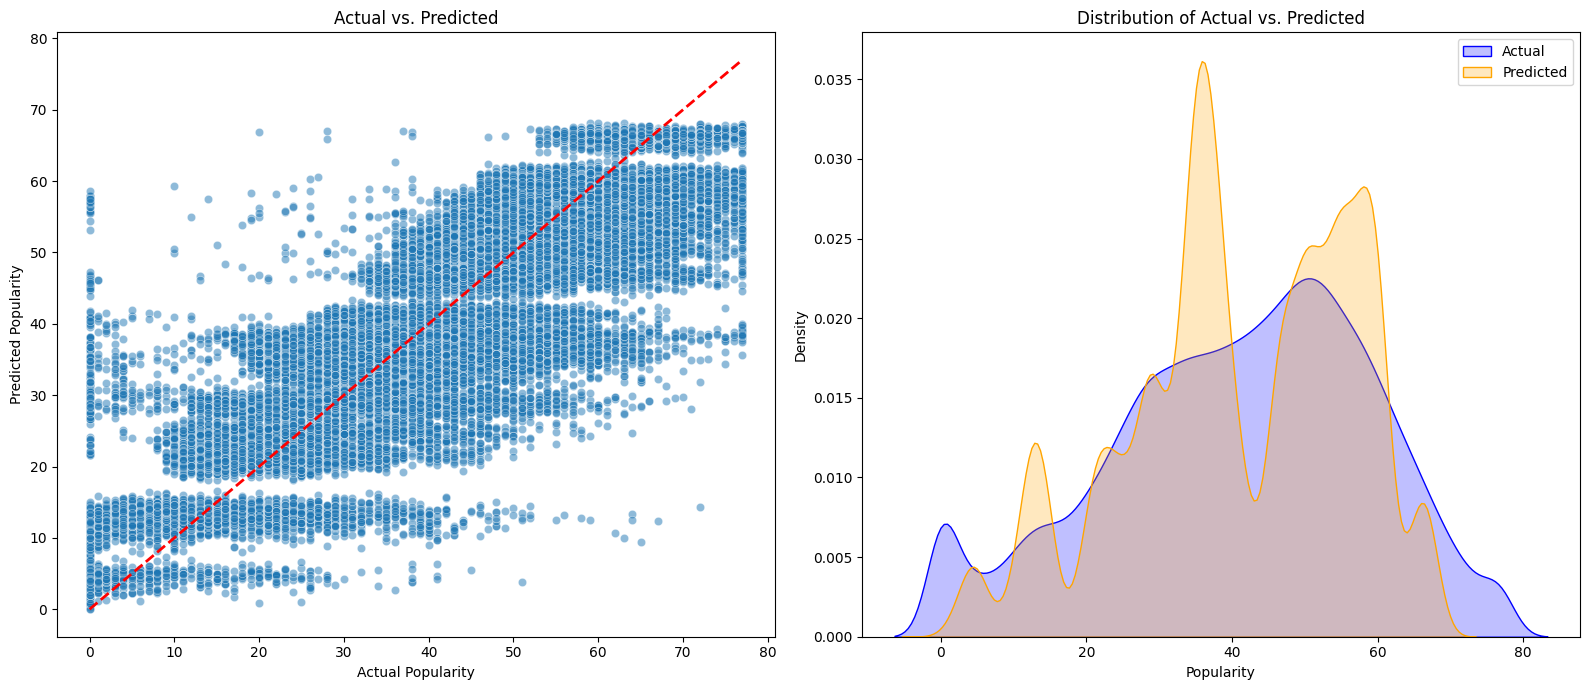

In [18]:
from sklearn.linear_model import LinearRegression
evaluate_sk(LinearRegression(fit_intercept=True))

R^2 :  0.743102971718137
MAE :  7.003352371559237
MSE :  84.17585536755891
RMSE :  9.174740070844456


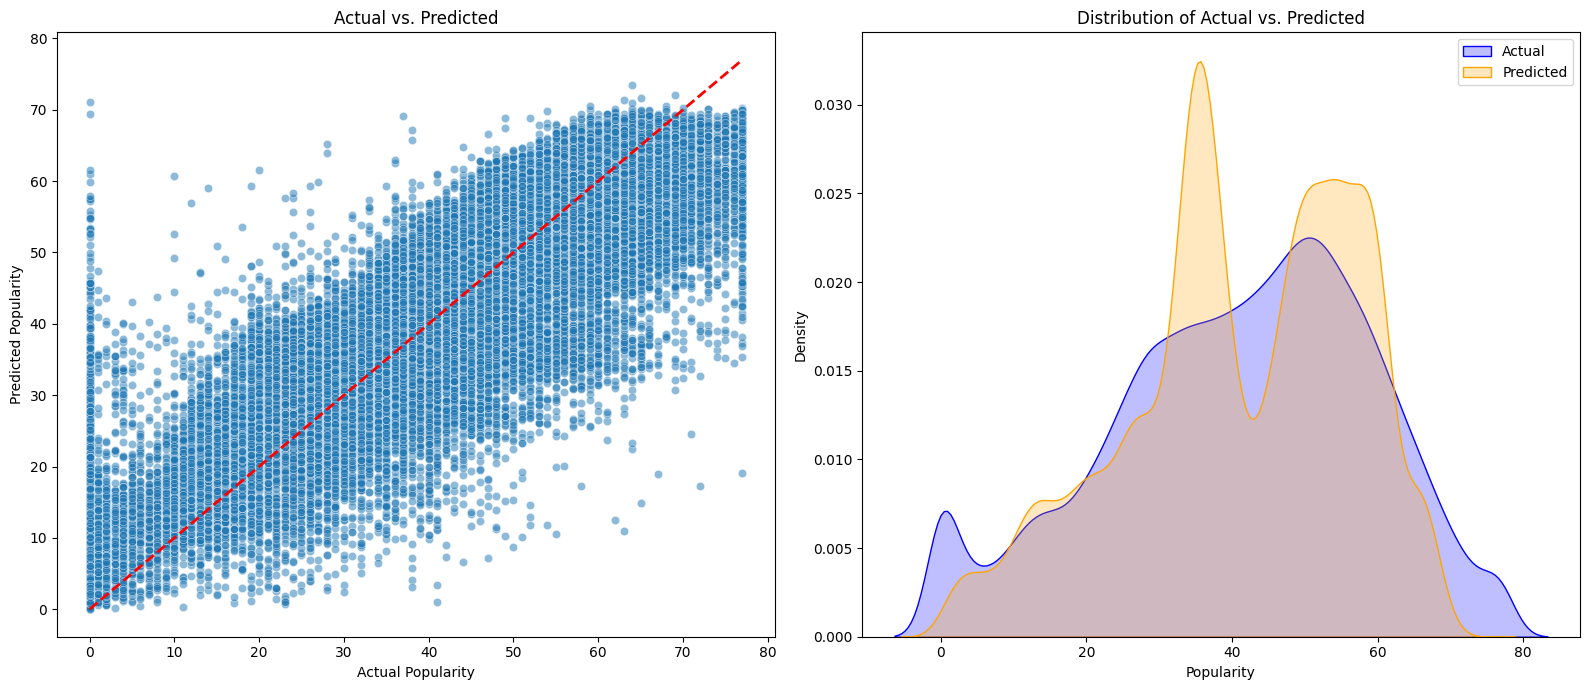

In [19]:
from sklearn.ensemble import RandomForestRegressor
rfr = RandomForestRegressor(n_estimators=128, n_jobs=-1, random_state=42)
evaluate_sk(rfr)

In [20]:
import matplotlib.pyplot as plt

def get_tree_best_features(model):
    feature_names = X_train.columns.values
    importances = model.feature_importances_
    std = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)
    
    indices_to_keep = [i for i in range(len(importances)) if importances[i] > 0.006]
    
    filtered_names = [feature_names[i] for i in indices_to_keep]
    filtered_importances = [importances[i] for i in indices_to_keep]
    filtered_std = [std[i] for i in indices_to_keep]
    
    
    forest_importances = pd.Series(filtered_importances, index=filtered_names)
    forest_importances = forest_importances.sort_values(ascending=False)
    
    fig, ax = plt.subplots()
    forest_importances.plot.bar(yerr=filtered_std, ax=ax)
    ax.set_title("Feature importances")
    ax.set_ylabel("Mean decrease in impurity")
    
    indices_to_keep_final = [i for i in range(len(importances)) if importances[i] > 0.015]
    filtered_names_final = [feature_names[i] for i in indices_to_keep]
    to_drop = [x for x in feature_names if x not in filtered_names_final]
    # Drop unnecessary features
    X_train_feature_selected = X_train.copy().drop(to_drop, axis=1)
    X_test_feature_selected = X_test.copy().drop(to_drop, axis=1)
    return (X_train_feature_selected, X_test_feature_selected)

R^2 :  0.7396663473604592
MAE :  7.038728534692329
MSE :  85.3019127486786
RMSE :  9.235903461420468


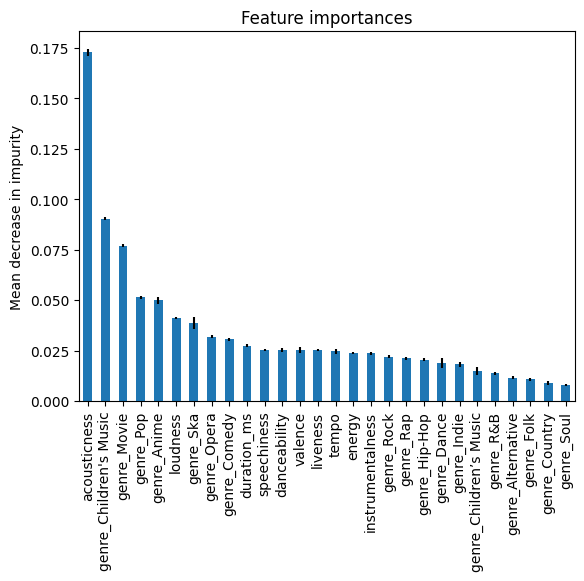

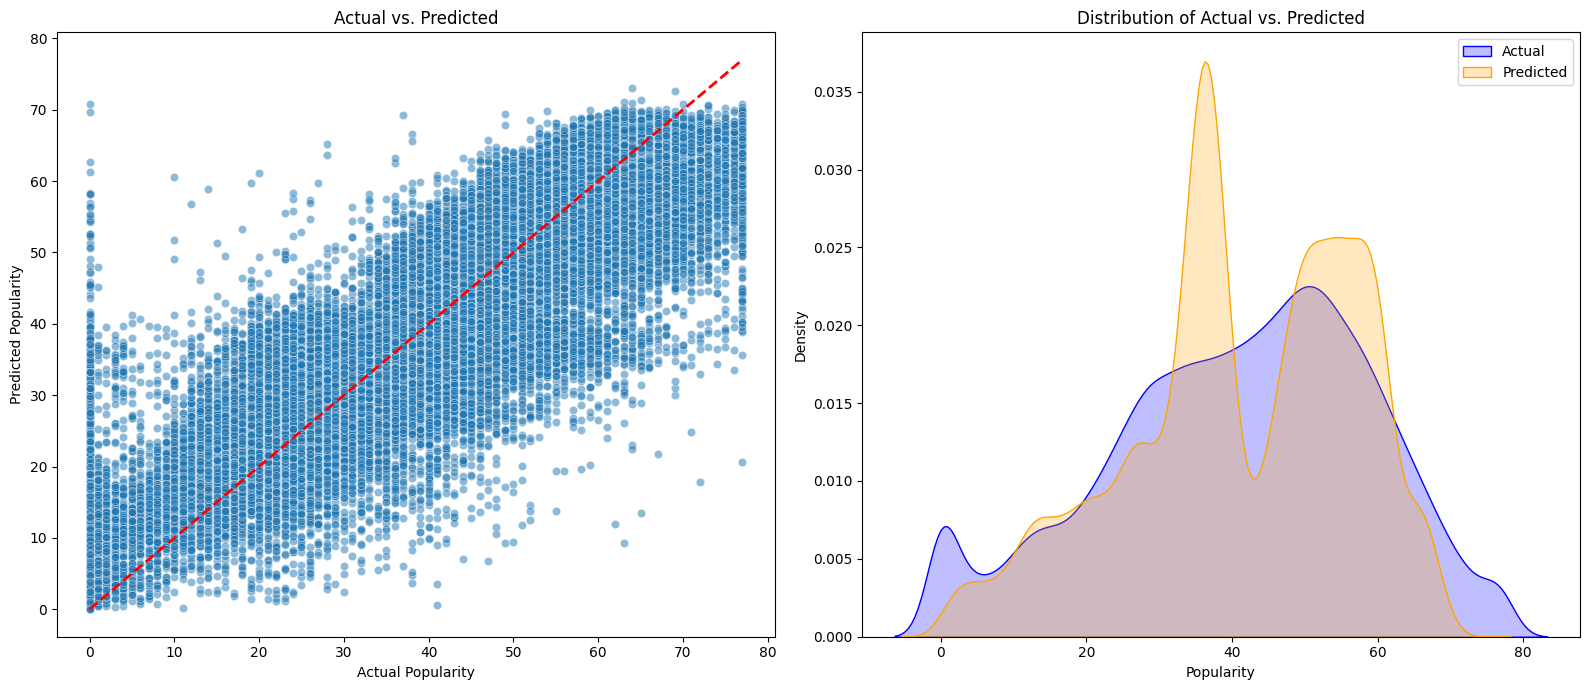

In [21]:
X_train_feature_selected, X_test_feature_selected = get_tree_best_features(rfr)
evaluate_sk(RandomForestRegressor(n_estimators=128, n_jobs=-1, random_state=42), X_train_feature_selected, X_test_feature_selected, id="RandomForestRegressorFeatureSelected")

R^2 :  0.7287458751711611
MAE :  7.178040016250294
MSE :  88.88015611606876
RMSE :  9.427627279229316


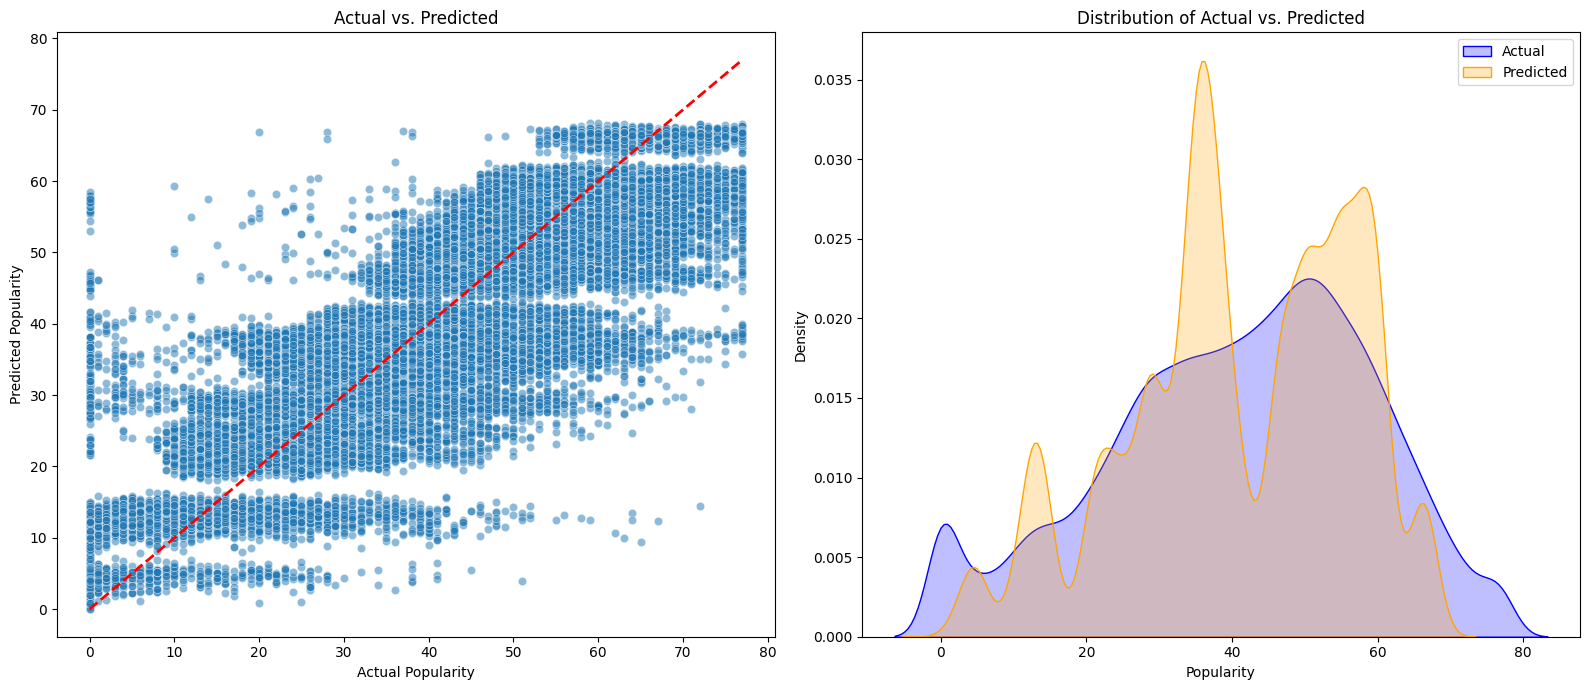

In [22]:
from sklearn.linear_model import Lasso
evaluate_sk(Lasso(alpha=0.001, max_iter=5000))

R^2 :  0.7287653965554794
MAE :  7.17726057058437
MSE :  88.87375966518744
RMSE :  9.427288033426551


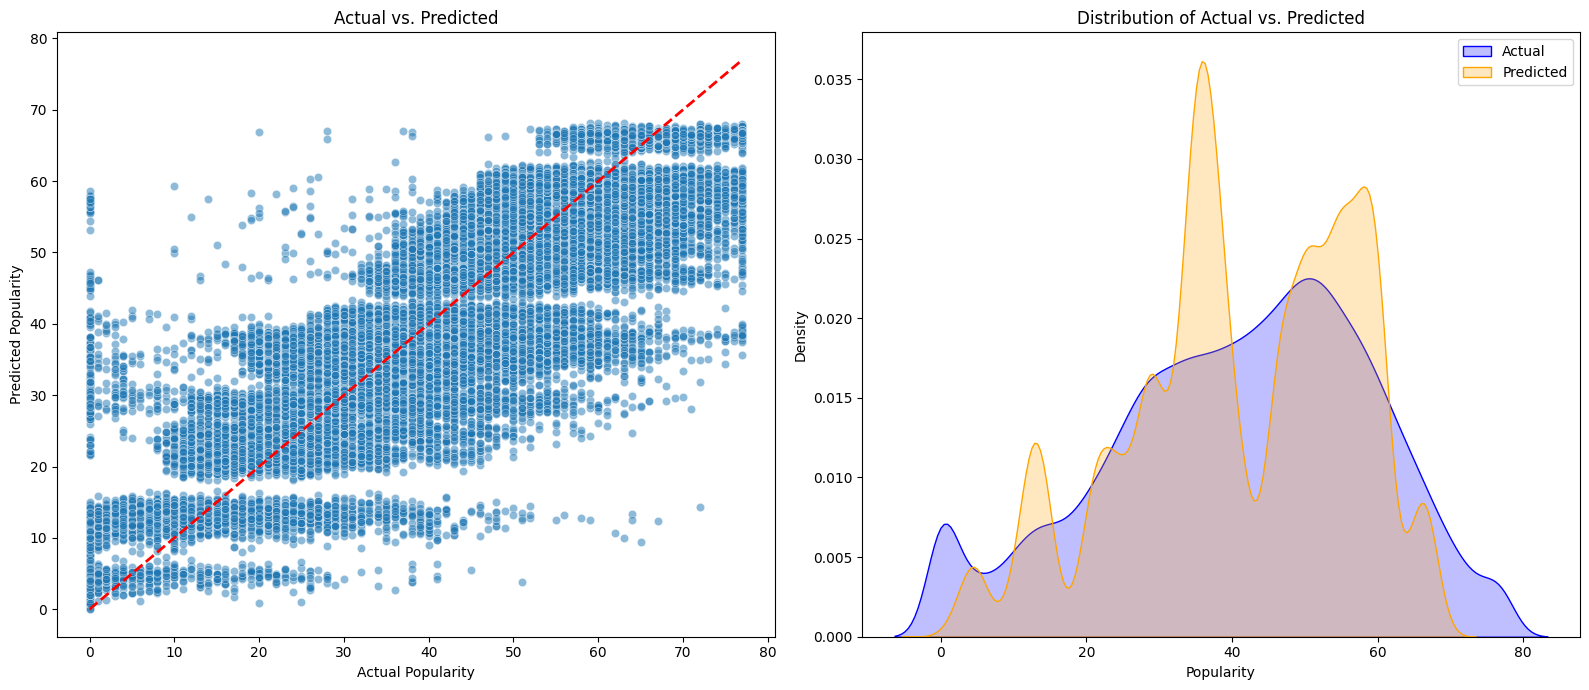

In [23]:
from sklearn.linear_model import Ridge
evaluate_sk(Ridge(alpha=0.01, solver="auto"))

R^2 :  0.7416562116674603
MAE :  7.024351295434268
MSE :  84.64990625709936
RMSE :  9.200538367785843


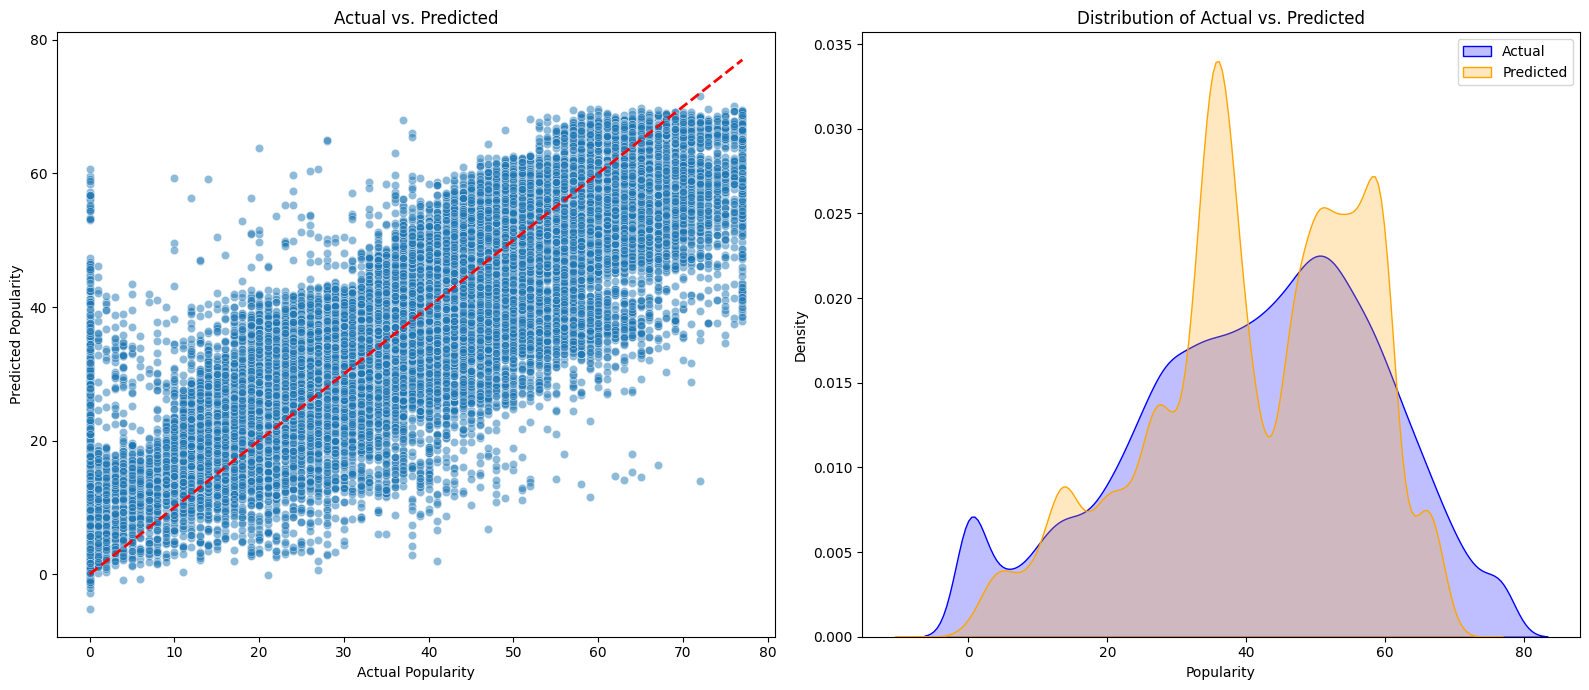

In [24]:
from sklearn.ensemble import GradientBoostingRegressor
evaluate_sk(GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.2, random_state=42))

R^2 :  0.7211928321397504
MAE :  7.059321597277771
MSE :  91.3550148641404
RMSE :  9.557981735917913


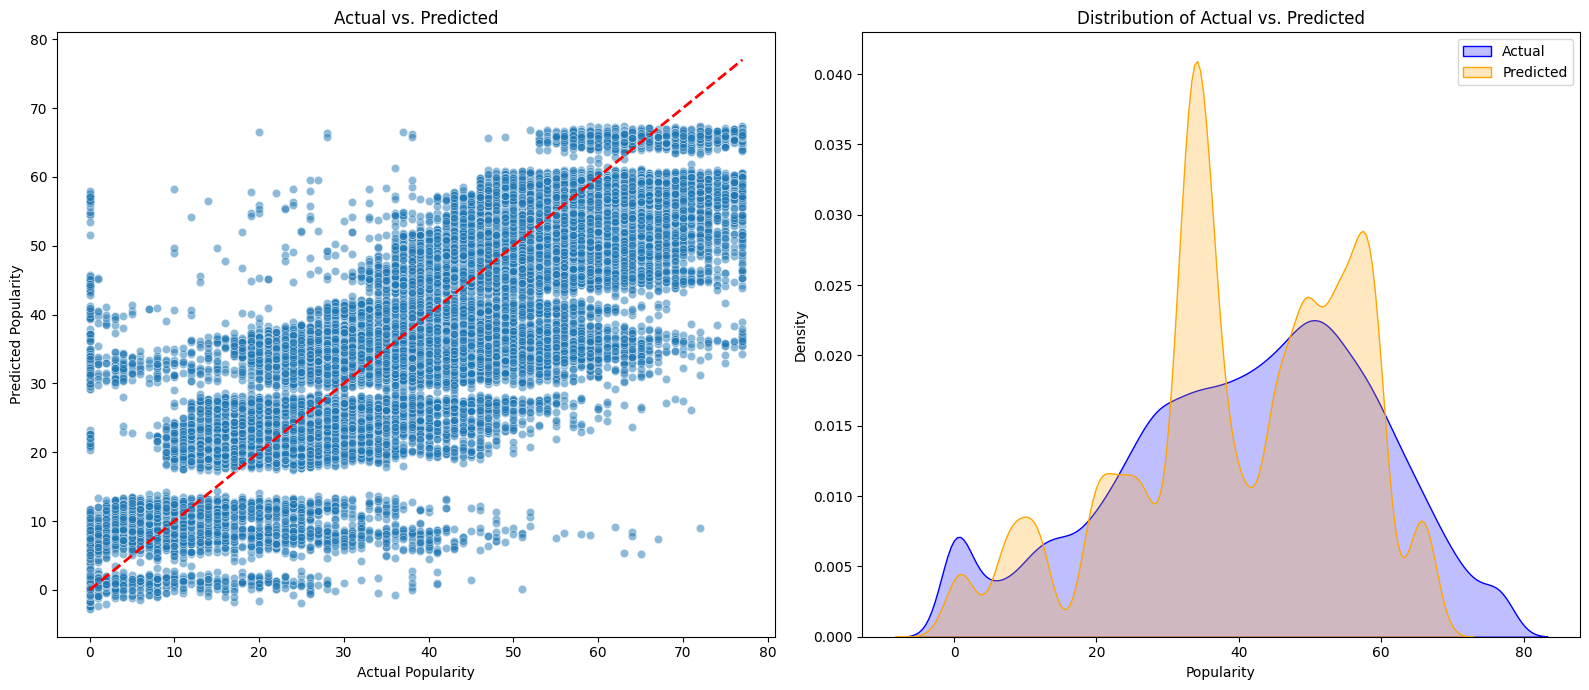

In [25]:
from sklearn.svm import LinearSVR # TOO MANY SAMPLES FOR SVR
evaluate_sk(LinearSVR())

R^2 :  0.7283918274647174
MAE :  7.178112880827669
MSE :  88.99616473138879
RMSE :  9.43377786103684


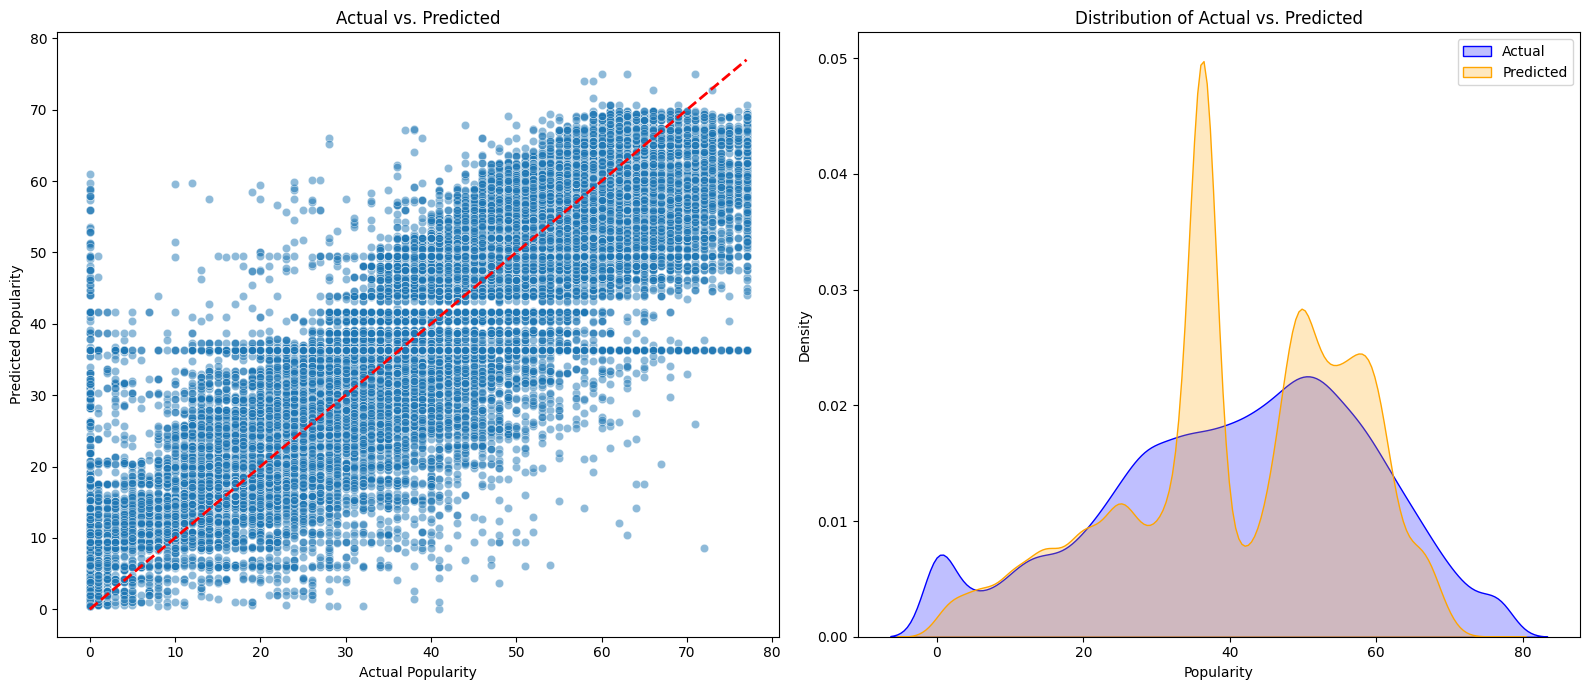

In [26]:
from sklearn.tree import DecisionTreeRegressor
evaluate_sk(DecisionTreeRegressor(random_state=42, max_depth=20, min_samples_split=330))

R^2 :  0.679832520839023
MAE :  7.728802816418699
MSE :  104.90729145251478
RMSE :  10.242426053065493


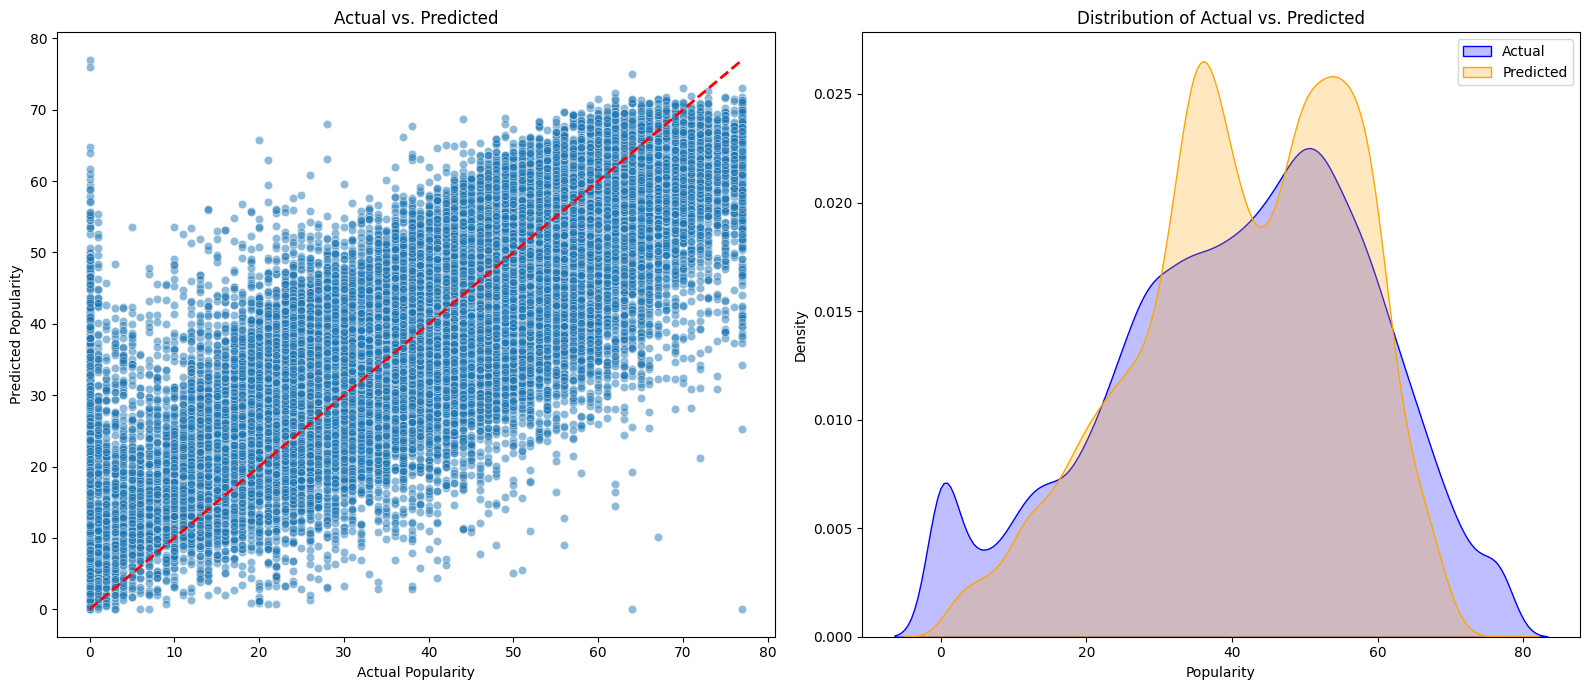

In [27]:
from sklearn.neighbors import KNeighborsRegressor
evaluate_sk(KNeighborsRegressor(n_neighbors=10, weights="distance"))

R^2 :  0.7524515390396118
MAE :  6.8577446937561035
MSE :  81.1126708984375
RMSE :  9.006257319133043


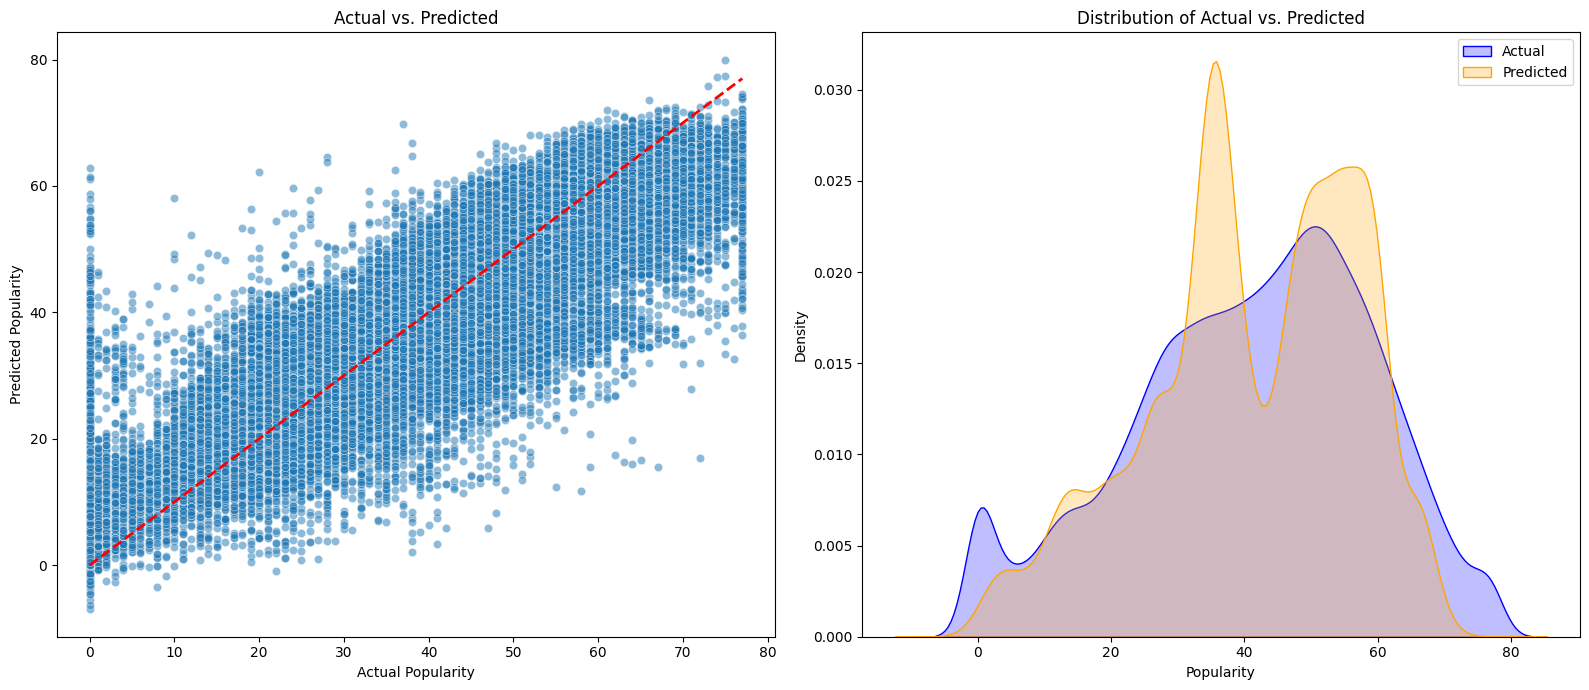

In [66]:
from xgboost import XGBRegressor
evaluate_sk(XGBRegressor(
    n_estimators=800,
    max_depth=6,
    learning_rate=0.1,
    reg_alpha=1.0, 
    reg_lambda=1.0, 
    min_child_weight=5,
    tree_method="hist", 
    random_state=42
))

In [58]:
import keras
from keras.layers import Dense
from keras.layers import Dropout
from keras.layers import BatchNormalization

def evaluate_keras(model, opt, loss="mse", id=None):
    model.compile(optimizer=opt, loss=loss)
    # keras.utils.plot_model(model)
    models[id] = {}#{"model": model, "train": X_train, "test": X_test}
    model.fit(X_train, y_train, batch_size=32, epochs=5)
    y_pred = model.predict(X_test).squeeze()
    evaluate(model, y_pred, id)

Epoch 1/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - loss: 207.1544
Epoch 2/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - loss: 142.1396
Epoch 3/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - loss: 134.5029
Epoch 4/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - loss: 129.1666
Epoch 5/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - loss: 126.9673
1455/1455 ━━━━━━━━━━━━━━━━━━━━ 1s 933us/step
R^2 :  0.7336814999580383
MAE :  7.059231758117676
MSE :  87.26292419433594
RMSE :  9.341462636778886


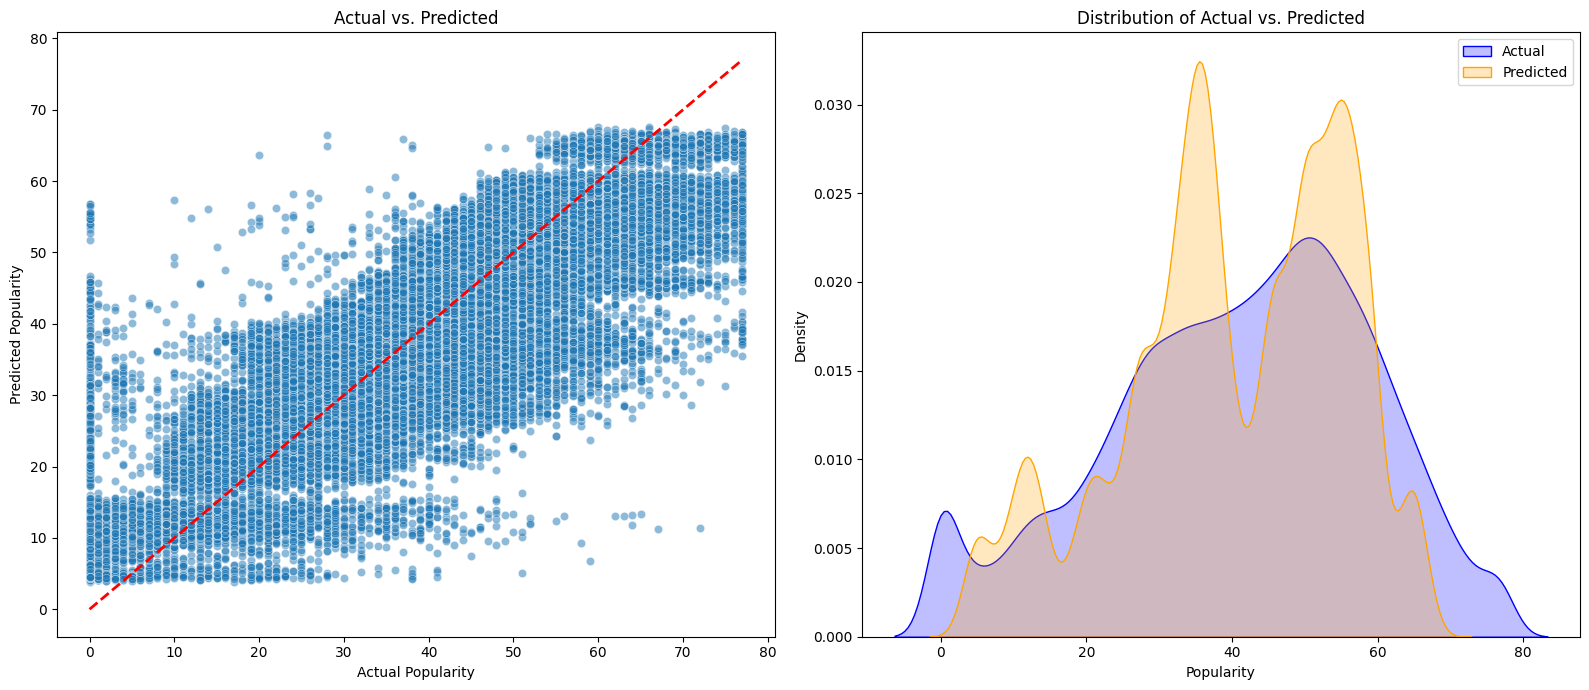

In [59]:
# Complex architecture
model_complex = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1)
])

evaluate_keras(model_complex, keras.optimizers.Nadam(learning_rate=0.001, clipnorm=1), id="Complex NN")

Epoch 1/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step - loss: 127.1032
Epoch 2/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 88.5241
Epoch 3/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 87.8885
Epoch 4/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 87.4891
Epoch 5/5
5816/5816 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - loss: 87.1139
1455/1455 ━━━━━━━━━━━━━━━━━━━━ 1s 830us/step
R^2 :  0.7371375560760498
MAE :  7.083987712860107
MSE :  86.13052368164062
RMSE :  9.280653192617459


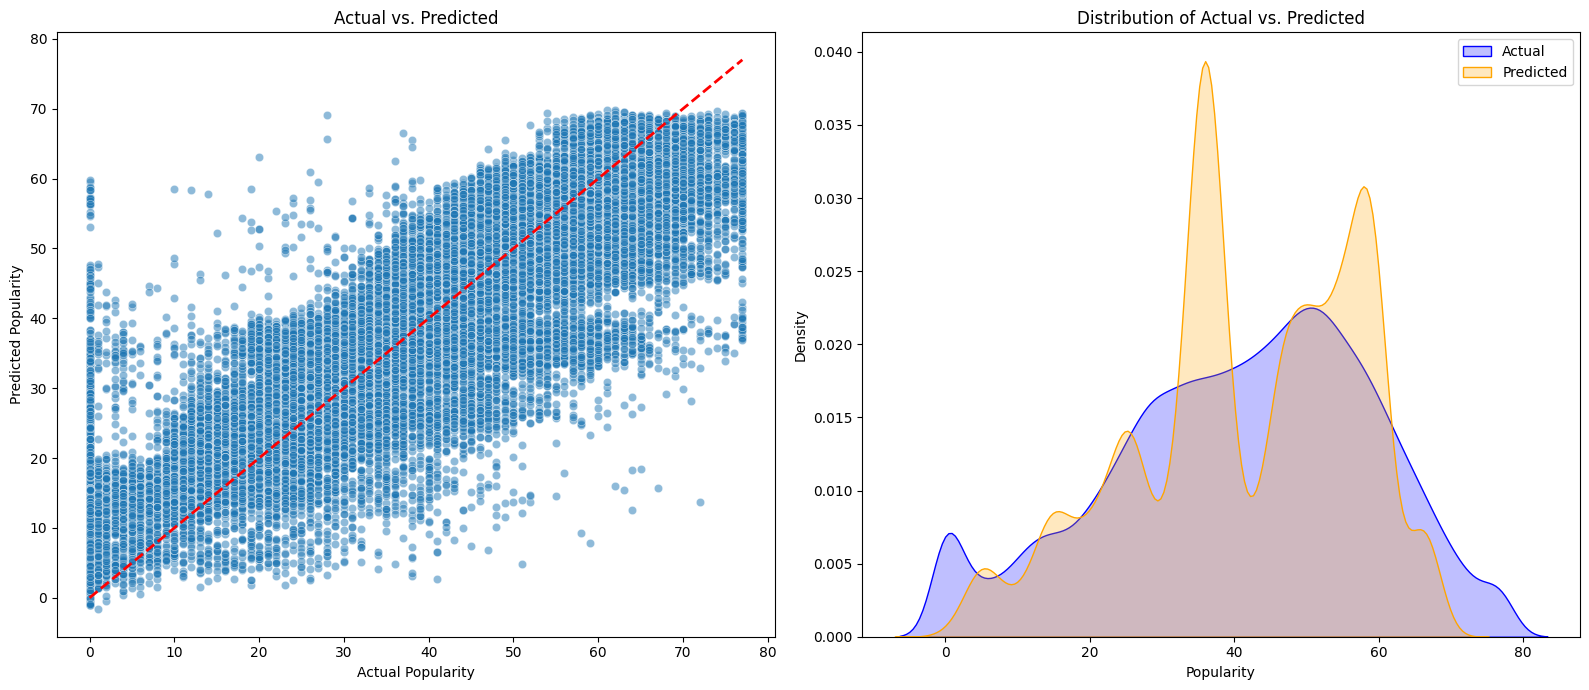

In [60]:
# Simple architecture
model_simple = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    Dense(256, activation='relu'),
    Dense(1)
])

evaluate_keras(model_simple, keras.optimizers.Nadam(learning_rate=0.001, clipnorm=1), id="Simple NN")

In [61]:
# Best model based on MAE
best_name = min(results, key=lambda x: results[x]["MAE"])
best_model = models[best_name]["model"]
best_model_train = models[best_name]["train"]
best_model_test = models[best_name]["test"]
print(f"Best Model: {best_name}")
print("R2:", results[best_name]["R2"])
print("MAE:", results[best_name]["MAE"])
print("MSE:", results[best_name]["MSE"])
# Need cross validation on best model, training only
print("Cross Validation, MAE, for best model")
cv_scores = cross_val_score(best_model, best_model_train, y_train, cv=5, scoring="neg_mean_absolute_error")
mae_scores = -cv_scores
print("MAE per fold:", mae_scores)
print("Mean MAE:", np.mean(mae_scores))
print("Standard Deviation:", np.std(mae_scores))
# Error analysis across popularity bins on test set
best_model.fit(best_model_train, y_train)
y_pred_best = best_model.predict(best_model_test)
bin_df = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred_best})
bin_df["Popularity Bin"] = pd.cut(bin_df["Actual"], bins=[0, 25, 50, 75, 100], labels=["Low", "Medium", "High", "Very High"], include_lowest = True)
print("Mean vs Predicted Popularity Bin")
display(bin_df.groupby("Popularity Bin")[["Actual", "Predicted"]].mean())
mae_per_bin = bin_df.groupby("Popularity Bin")[["Actual", "Predicted"]].apply(lambda x: np.mean(np.abs(x["Actual"]-  x["Predicted"]))).rename("MAE")
print("MAE per Popularity Bin")
display(mae_per_bin)

Best Model: XGBRegressor
R2: 0.7454450726509094
MAE: 6.9658002853393555
MSE: 83.40843200683594
Cross Validation, MAE, for best model
MAE per fold: [7.04089499 7.0521965  7.0722599  6.98288631 7.0097971 ]
Mean MAE: 7.031606960296631
Standard Deviation: 0.03166142737169259
Mean vs Predicted Popularity Bin


C:\Users\carp\AppData\Local\Temp\ipykernel_2636\2545130841.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(bin_df.groupby("Popularity Bin")[["Actual", "Predicted"]].mean())


,Actual,Predicted
Popularity Bin,,
Low,13.617816,20.125816
Medium,38.805598,39.612610
High,59.309333,54.895092
Very High,76.808149,60.859402


MAE per Popularity Bin


C:\Users\carp\AppData\Local\Temp\ipykernel_2636\2545130841.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mae_per_bin = bin_df.groupby("Popularity Bin")[["Actual", "Predicted"]].apply(lambda x: np.mean(np.abs(x["Actual"]-  x["Predicted"]))).rename("MAE")


Popularity Bin
Low           8.147297
Medium        6.236293
High          6.931753
Very High    15.948748
Name: MAE, dtype: float64

In [67]:
results_df = pd.DataFrame.from_dict(results, orient='index')
results_df

,R2,MAE,MSE,RMSE
DummyRegressor,-0.000067,14.820443,327.685890,18.102096
LinearRegression,0.728765,7.177259,88.873750,9.427288
RandomForestRegressor,0.743103,7.003352,84.175855,9.174740
RandomForestRegressorFeatureSelected,0.739666,7.038729,85.301913,9.235903
Lasso,0.728746,7.178040,88.880156,9.427627
Ridge,0.728765,7.177261,88.873760,9.427288
GradientBoostingRegressor,0.741656,7.024351,84.649906,9.200538
LinearSVR,0.721193,7.059322,91.355015,9.557982
DecisionTreeRegressor,0.728392,7.178113,88.996165,9.433778
KNeighborsRegressor,0.679833,7.728803,104.907291,10.242426


# Critical Thinking and Problem Solving Reflection
Throughout the project, the team followed a structured machine learning workflow that required a lot of communication in order to make informed decisions at each stage of the process. Our exploratory data analysis helped us identify the underlying distribution of popularity and the relationships among different features. Doing all of this helped guide our early choices in data preparation, like removing the identifiers, handling any missed data, working around the duplicates, winsorizing skewed data, etc. All of these steprs were done based off patterns learned in class and in our data.

When we began to build our models, we avoided relying on a single algorithm. We went ahead and evaluated using all the regrwssion models taught in class like Gradient Boosting, Linear SVR, Simple Neural Networks, Random Forest, Decision Trees, and Linear Regression. We then compared these models usinf R^2, MAE, and MSE to see how the algorithms handled the structure and complexity of our dataset. After all of this, we decided to select the best model based on MAE after intrepreting the tradeoffs in the metrics.

To further validate our choice, we went ahead and performed a 5-fold cross-validation, which ensures that the final model chosen was stable across the different subsets of the training data. In addition we went ahead and performed error analysis across popularity bins to understand whether the model struggled more at predicting certain ranges of popularity. We were able to see the natural imbalance in the target variable and evaluate fairness and performance beyond a single aggregate metric.

All in all, this project forced us to continuously think as a team and find reasoning before each decision before actually doing it.By cleaning the data, comparing models, validating results with cross-validation, and examining errors across the popularity levels, we were able to create a thoughtful problem-solving approach.